In [1]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Flatten, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os  # Operating system interfaces
import tensorflow as tf                                    # TensorFlow deep learning framework
import matplotlib.pyplot as plt                            # Plotting library
import matplotlib.image as mpimg  
from tensorflow.keras.callbacks import EarlyStopping  
from PIL import Image
import seaborn as sns

import numpy as np
from sklearn.metrics import classification_report
import time 

2025-08-10 10:30:15.059396: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1754821815.257066      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1754821815.318590      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
# Train Generator
training_set = ImageDataGenerator(rescale=1.0/255.0).flow_from_directory(
    '/kaggle/input/mscthesistomatoaug25/train',
     target_size=(224, 224),    # Resize all images to 224x224
    batch_size=32,             # Number of images to be yielded from the generator per batch
    class_mode='categorical',  # Use categorical labels for multi-class classification
    shuffle=True,              # Shuffle the dataset
    color_mode='rgb'           # Set color mode (RGB)
)

Found 10500 images belonging to 10 classes.


In [3]:
validation_set = ImageDataGenerator(rescale=1.0/255.0).flow_from_directory(
    '/kaggle/input/mscthesistomatoaug25/val',
     target_size=(224, 224),    # Resize all images to 128x128
     batch_size=32,             # Number of images to be yielded from the generator per batch
     class_mode='categorical',  # Use categorical labels for multi-class classification
     shuffle=True,              # Shuffle the dataset
     color_mode='rgb'           # Set color mode (RGB)
)

Found 3638 images belonging to 10 classes.


(256, 256, 4)


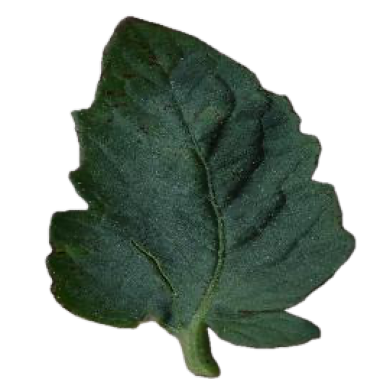

In [4]:
image_path = '/kaggle/input/mscthesistomatoaug25/train/Tomato___Bacterial_spot/image (1) Background Removed.png'

# Read the image
img = mpimg.imread(image_path)

print(img.shape)
# Display the image
plt.imshow(img)
plt.axis('off')  # Turn off axis numbers
plt.show()

In [5]:
image_path = '/kaggle/input/mscthesistomatoaug25/train/Tomato___Bacterial_spot/image (1) Background Removed.png'

# Read the image
img = mpimg.imread(image_path)

print(img)

[[[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 ...

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  ...
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]]


In [6]:
for x, y in training_set:
    print(x,x.shape)
    print(y,y.shape)
    break

[[[[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  ...

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]]


 [[[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  ...

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0

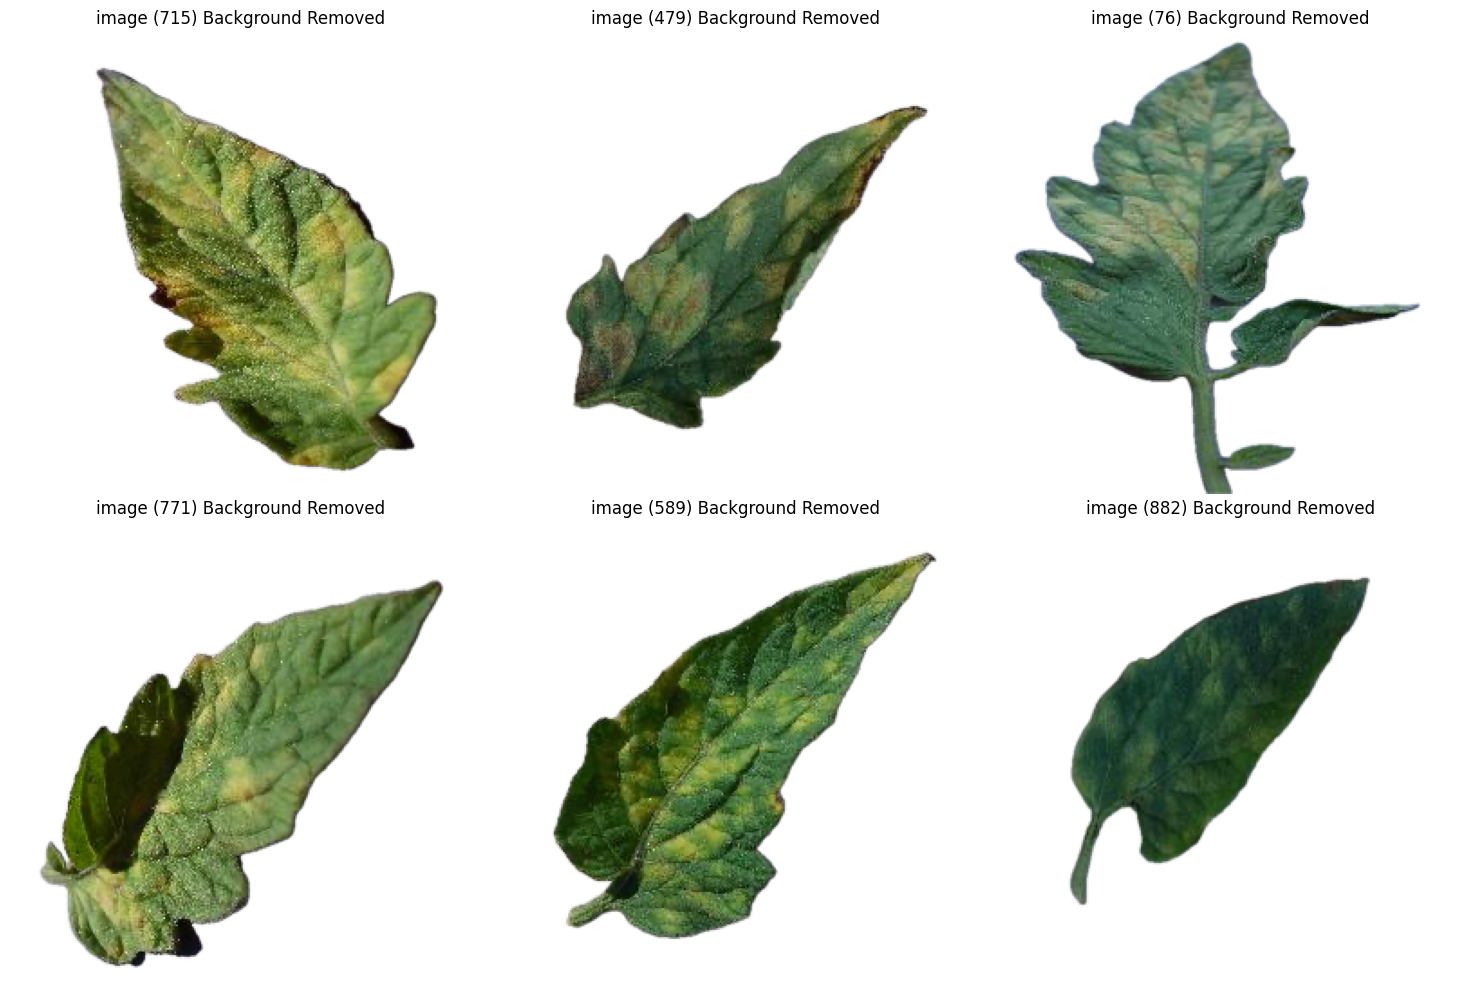

In [7]:
# Path to the directory containing images
path = "/kaggle/input/mscthesistomatoaug25/train/Tomato___Leaf_Mold"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()

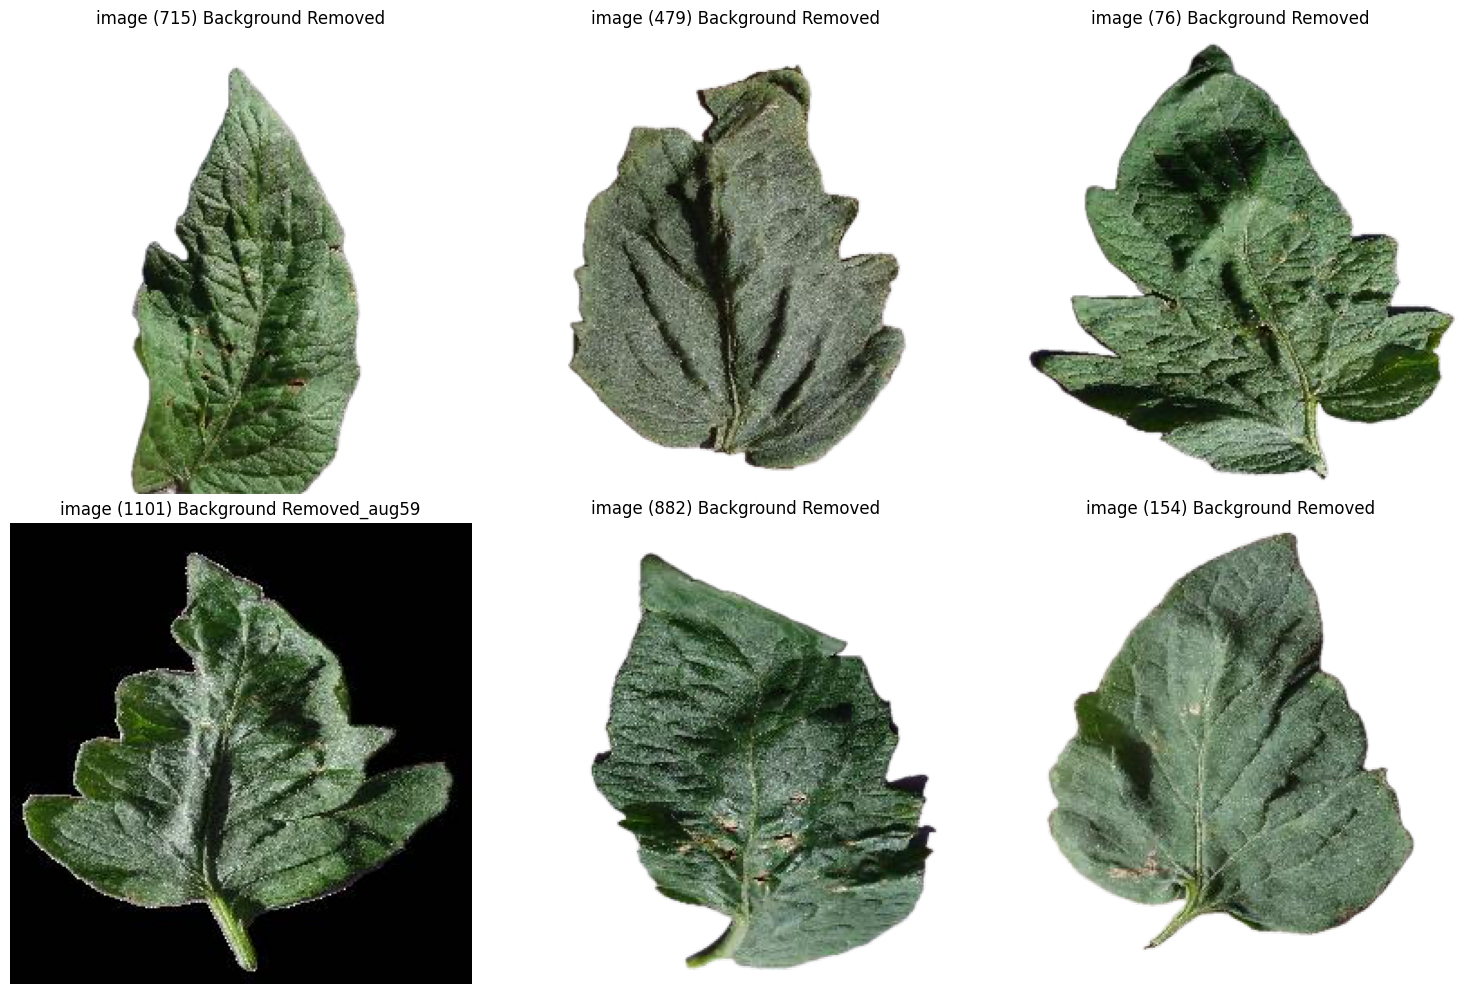

In [8]:
# Path to the directory containing images
path = "/kaggle/input/mscthesistomatoaug25/train/Tomato___Target_Spot"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()

In [9]:
image_size = (224, 224)

In [10]:
# Load the InceptionV3 model
image_input = Input(shape=(*image_size, 3))
inception_model = InceptionV3(input_tensor=image_input, weights='imagenet', include_top=False)

I0000 00:00:1754821842.782829      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1754821842.783500      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
# Add a new classification layer
x = inception_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
class_outputs = Dense(10, activation='softmax')(x)

In [12]:
# Create the model
model = Model(inputs=inception_model.input, outputs=class_outputs)

In [13]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 111, 111,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 111, 111,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 111, 111,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 109, 109,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 109, 109,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 54, 54,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 54, 54,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 54, 54,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 52, 52,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 52, 52,    │          0 │ batch_normalizat

 Total params: 22,066,346 (84.18 MB)

 Trainable params: 22,031,914 (84.05 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [14]:
# Compile the Model
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True)
# Training the Model
training_history = model.fit(x=training_set,validation_data=validation_set,epochs=100, callbacks=[early_stopping])

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(None, 224, 224, 3))
  warnings.warn(msg)
I0000 00:00:1754821899.903327      79 service.cc:148] XLA service 0x7adfe0003b10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1754821899.904060      79 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1754821899.904081      79 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1754821905.098070      79 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1754821936.484408      79 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


329/329 ━━━━━━━━━━━━━━━━━━━━ 267s 540ms/step - accuracy: 0.6211 - loss: 1.1338 - val_accuracy: 0.9340 - val_loss: 0.2128
Epoch 2/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 96s 290ms/step - accuracy: 0.9513 - loss: 0.1762 - val_accuracy: 0.9332 - val_loss: 0.2286
Epoch 3/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 288ms/step - accuracy: 0.9724 - loss: 0.0936 - val_accuracy: 0.9656 - val_loss: 0.1023
Epoch 4/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 289ms/step - accuracy: 0.9794 - loss: 0.0703 - val_accuracy: 0.9519 - val_loss: 0.1670
Epoch 5/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 94s 286ms/step - accuracy: 0.9807 - loss: 0.0640 - val_accuracy: 0.9747 - val_loss: 0.0948
Epoch 6/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 287ms/step - accuracy: 0.9842 - loss: 0.0512 - val_accuracy: 0.9722 - val_loss: 0.1037
Epoch 7/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 288ms/step - accuracy: 0.9871 - loss: 0.0493 - val_accuracy: 0.9819 - val_loss: 0.0741
Epoch 8/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 287ms/step - accuracy: 0.9890 - loss: 0.03

In [16]:
#Training set Accuracy
train_loss, train_acc = model.evaluate(training_set)
print(f"Training Accuracy: {train_acc * 100:.2f}%")

329/329 ━━━━━━━━━━━━━━━━━━━━ 35s 105ms/step - accuracy: 0.9968 - loss: 0.0085
Training Accuracy: 99.70%


In [17]:
# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_set)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Evaluating model...
114/114 ━━━━━━━━━━━━━━━━━━━━ 12s 105ms/step - accuracy: 0.9823 - loss: 0.0845
Validation Accuracy: 98.19%


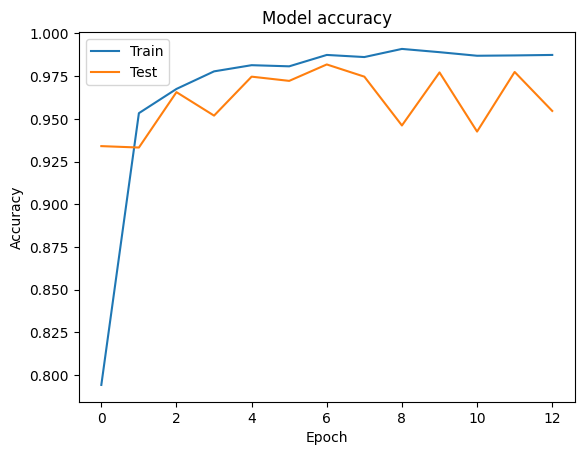

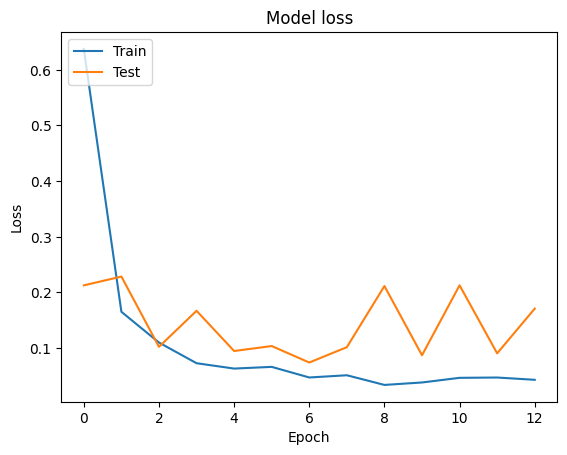

In [18]:
# Plot training & validation accuracy values
plt.plot(training_history.history['accuracy'])
plt.plot(training_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(training_history.history['loss'])
plt.plot(training_history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

In [19]:
# Function to Load and Preprocess the Image using Pillow
def load_and_preprocess_image(image_path, target_size=(224, 224)):
    # Load the image
    img = Image.open(image_path)
    # Resize the image
    img = img.resize(target_size)
    # Convert the image to a numpy array
    img_array = np.array(img)
    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)
    # Scale the image values to [0, 1]
    img_array = img_array.astype('float32') / 255.
    return img_array

# Function to Predict the Class of an Image
def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name

In [20]:
# Create a mapping from class indices to class names
class_indices = {v: k for k, v in training_set.class_indices.items()}
class_indices

{0: 'Tomato___Bacterial_spot',
 1: 'Tomato___Early_blight',
 2: 'Tomato___Late_blight',
 3: 'Tomato___Leaf_Mold',
 4: 'Tomato___Septoria_leaf_spot',
 5: 'Tomato___Spider_mites Two-spotted_spider_mite',
 6: 'Tomato___Target_Spot',
 7: 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 8: 'Tomato___Tomato_mosaic_virus',
 9: 'Tomato___healthy'}

In [21]:
# Example Usage
# image_path = '/kaggle/input/tomato-balanced-nobg15k/val/Tomato___Leaf_Mold/0185befe-f0b5-4848-9677-f33c2237f4e9___Crnl_L.Mold_8729_aug_480_13.png'

# predicted_class_name = predict_image_class(model, image_path, class_indices)

# # Output the result
# print("Predicted Class Name:", predicted_class_name)

In [22]:
class_name = [class_indices[i] for i in range(len(class_indices))]
class_name

['Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Target_Spot',
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'Tomato___Tomato_mosaic_virus',
 'Tomato___healthy']

In [23]:
test_set =  ImageDataGenerator(rescale=1.0/255.0).flow_from_directory(
    '/kaggle/input/mscthesistomatoaug25/test',
    target_size=(224, 224),    # Resize all images to 224x224
     batch_size=32,             # Number of images to be yielded from the generator per batch
     class_mode='categorical',  # Use categorical labels for multi-class classification
     shuffle=False,              # Shuffle the dataset
     color_mode='rgb'
)

Found 1821 images belonging to 10 classes.


In [24]:
y_pred = model.predict(test_set)

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(32, 224, 224, 3))
  warnings.warn(msg)


57/57 ━━━━━━━━━━━━━━━━━━━━ 31s 441ms/step


In [25]:
predicted_categories = np.argmax(y_pred, axis=1)
predicted_categories

array([0, 0, 0, ..., 9, 9, 9])

In [26]:
y_true = test_set.classes

In [27]:
from sklearn.metrics import accuracy_score
# Calculate Test Accuracy
test_accuracy = accuracy_score(y_true, predicted_categories)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 97.91%


In [28]:
 from sklearn.metrics import confusion_matrix,classification_report
 cm = confusion_matrix(y_true,predicted_categories)

In [29]:
# Precision Recall Fscore
print(classification_report(y_true,predicted_categories,target_names=class_name))

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.98      0.97      0.97       213
                        Tomato___Early_blight       0.99      0.89      0.94       100
                         Tomato___Late_blight       0.96      0.99      0.98       191
                           Tomato___Leaf_Mold       0.96      1.00      0.98        96
                  Tomato___Septoria_leaf_spot       0.98      0.96      0.97       178
Tomato___Spider_mites Two-spotted_spider_mite       1.00      0.95      0.97       168
                         Tomato___Target_Spot       0.93      0.99      0.96       141
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      1.00      1.00       536
                 Tomato___Tomato_mosaic_virus       0.95      1.00      0.97        38
                             Tomato___healthy       1.00      0.99      0.99       160

                                     accu

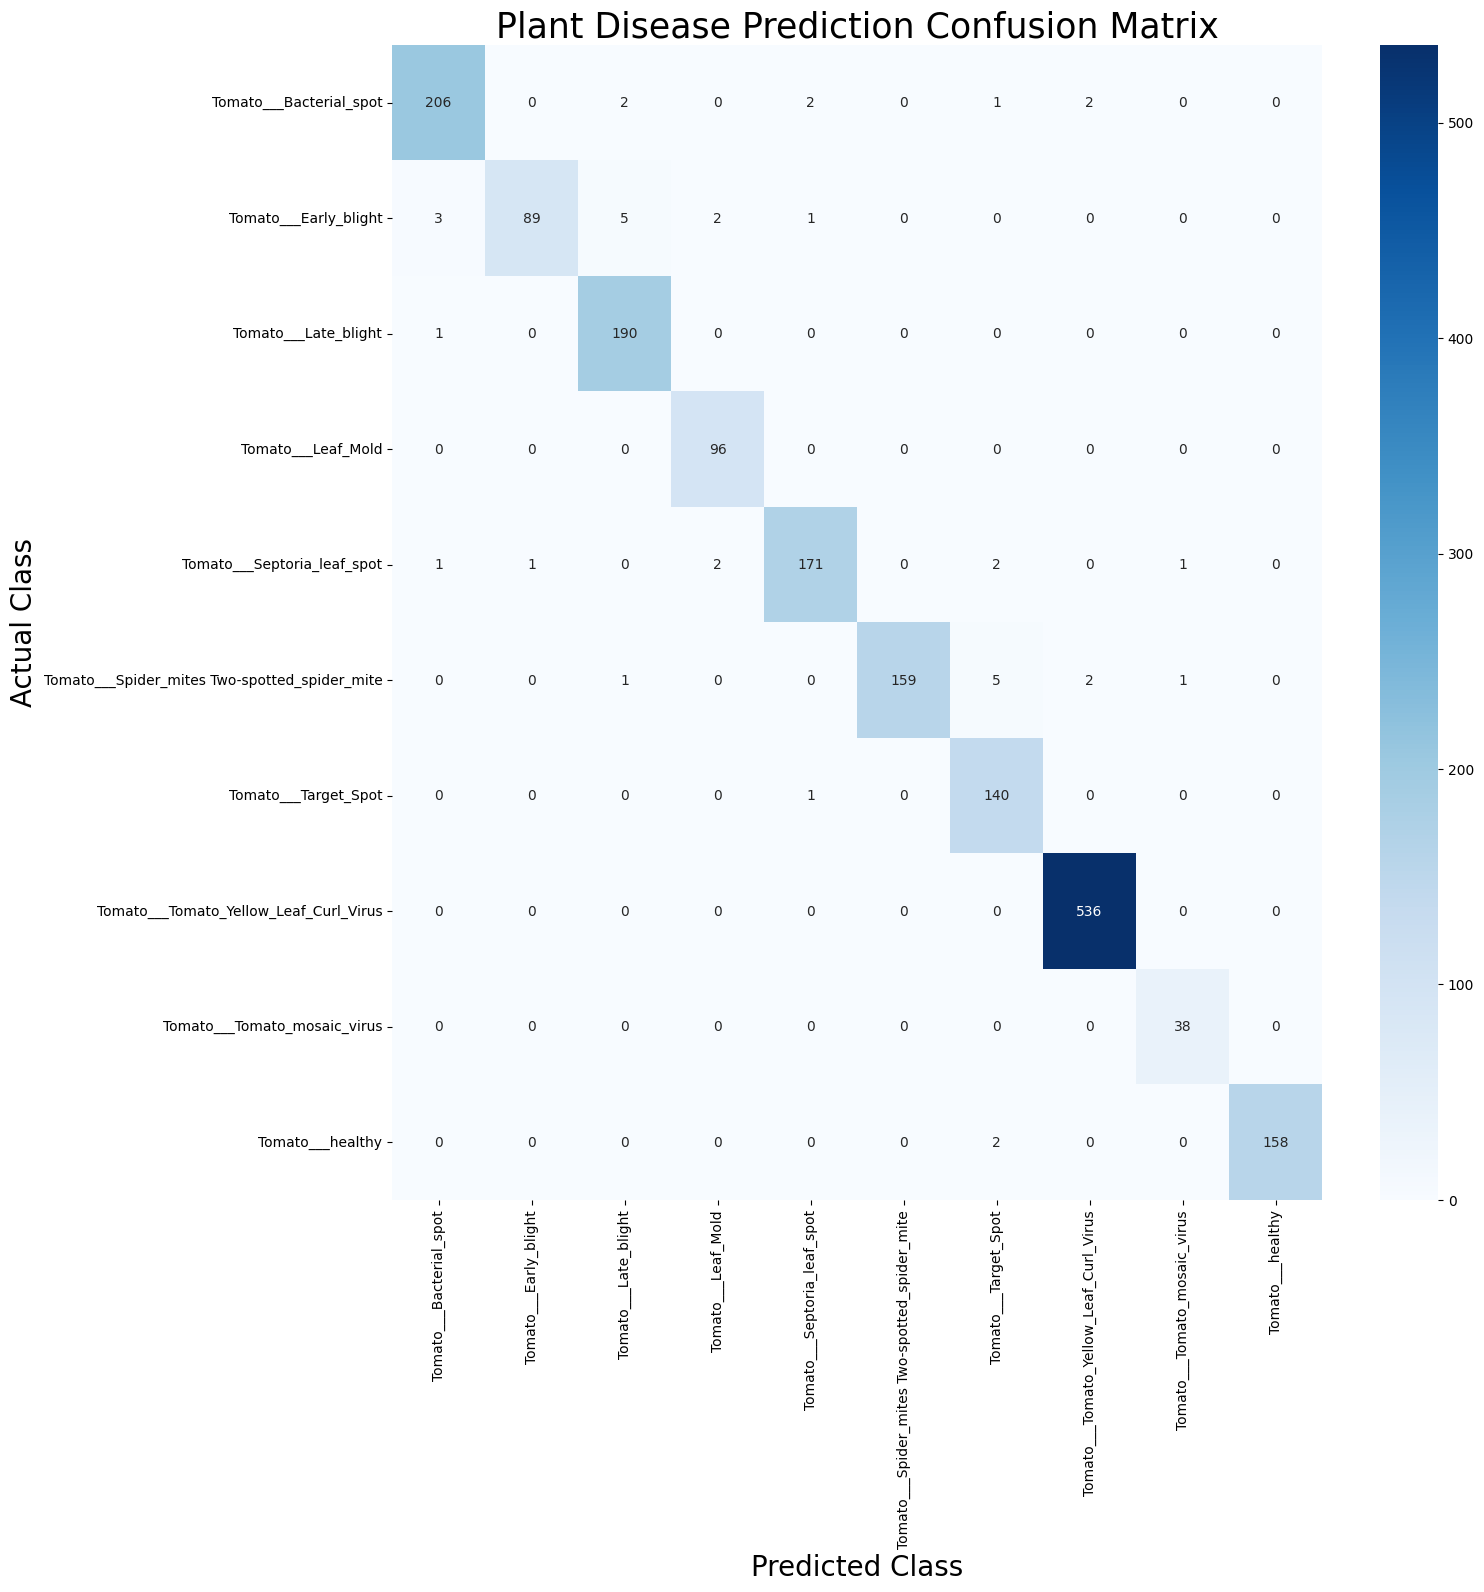

In [30]:
 plt.figure(figsize=(15, 15))
 #sns.heatmap(cm,annot=True,annot_kws={"size": 20})
sns.heatmap(cm, annot=True, xticklabels=class_name, yticklabels=class_name, fmt='g', cmap='Blues')


 plt.xlabel('Predicted Class',fontsize = 20)
 plt.ylabel('Actual Class',fontsize = 20)
 plt.title('Plant Disease Prediction Confusion Matrix',fontsize = 25)
 plt.show()

In [31]:
model.save('inceptionv3_tomato.h5')